# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-03-07
> - Modified: 2026-01-07
---

> - [60k Human PBMCs Stained with 8 TotalSeq™-B Human Hashtags (Donor 1-4, 4 samples)](https://www.10xgenomics.com/cn/datasets/60k_Human_TotalSeqB_hashing_3p_gem-x)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - 10X Universal 3' v4 scRNA-seq
> - Cell Surface Protein: Hashtag oligos (HTOs)
> - 2024-11-19
---

# Experimental Design

> - 10x Genomics Cell Surface Protein Labeling for Single Cell RNA Sequencing Protocols with Feature Barcode technology (CG000149, Rev D)
> - Cells from the four donors were multiplexed at roughly equal proportions with two hashtags per donor, resulting in a pooled sample labeled with 8 hashtags.
> - Chromium GEM-X Single Cell 3' Reagent Kits v4 with Feature Barcode technology for Cell Surface Protein User Guide (CG000732)
> - Chromium X Series
> - Illumina NovaSeq 6000
> - Cell Ranger v9.0.0
>     - multi

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donors 1~4 | PBMCs | Peripheral blood mononuclear cells | - | - | Diseased |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv4_60k"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [4]:
samples <- file.path(data_dir, "matrix") |>
    list.files(full.names = FALSE, recursive = TRUE) |>
    grep("filtered_feature_bc_matrix.h5", x = _, value = TRUE)

names(samples) <- file.path(data_dir, "matrix") |>
    list.dirs(full.names = FALSE, recursive = FALSE)

paste(names(samples), samples, sep = ": ") |> cat(sep = "\n")

Donor1: Donor1/filtered_feature_bc_matrix.h5
Donor2: Donor2/filtered_feature_bc_matrix.h5
Donor3: Donor3/filtered_feature_bc_matrix.h5
Donor4: Donor4/filtered_feature_bc_matrix.h5


In [5]:
load_mtx_to_seurat <- function(path, sample, name = sample) {

    counts <- file.path(path, sample) |> 
        Read10X_h5()

    obj <- CreateSeuratObject(
        counts[["Gene Expression"]], project = name)
    rownames(counts[["Antibody Capture"]]) <- gsub(
        "_", "-", rownames(counts[["Antibody Capture"]]))
    obj[["HTO"]] <- CreateAssayObject(
        counts = counts[["Antibody Capture"]])
    return(obj)
}

In [6]:
scrna_list <- mapply(
    FUN = load_mtx_to_seurat,
    sample = samples,
    name = names(samples),
    MoreArgs = list(path = file.path(data_dir, "matrix")), 
    SIMPLIFY = FALSE)

Genome matrix has multiple modalities, returning a list of matrices for this genome

Genome matrix has multiple modalities, returning a list of matrices for this genome

Genome matrix has multiple modalities, returning a list of matrices for this genome

Genome matrix has multiple modalities, returning a list of matrices for this genome



In [7]:
scrna_list

$Donor1
An object of class Seurat 
38614 features across 9596 samples within 2 assays 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts
 1 other assay present: HTO

$Donor2
An object of class Seurat 
38614 features across 10235 samples within 2 assays 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts
 1 other assay present: HTO

$Donor3
An object of class Seurat 
38614 features across 8991 samples within 2 assays 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts
 1 other assay present: HTO

$Donor4
An object of class Seurat 
38614 features across 10885 samples within 2 assays 
Active assay: RNA (38606 features, 0 variable features)
 1 layer present: counts
 1 other assay present: HTO


# 2. Quality Control

In [8]:
cell_stats <- function(obj_list) {
    cells_per_object <- vapply(
        obj_list, function(x) length(Cells(x)), 
        FUN.VALUE = integer(1))
    total_cells <- sum(cells_per_object)
    
    c(cells_per_object, Total = total_cells)
}

In [9]:
scrna_list |> cell_stats() |> print()

Donor1 Donor2 Donor3 Donor4  Total 
  9596  10235   8991  10885  39707 


## 1). Filtering Genes

In [10]:
filter_low_detected_genes <- function(
    obj_list, min_cells = 3) {

    genes_list <- lapply(obj_list, function(obj){
        mat <- LayerData(obj, layer = "counts")
        gene_detect <- rowSums(mat > 0)
        names(gene_detect[gene_detect >= min_cells])
    })
    names(genes_list) <- names(obj_list)
    
    keep_genes <- Reduce(union, genes_list)
    
    message("Genes after filtering in each layer:")
    print(lengths(genes_list))
    message("Final intersected gene count: ", length(keep_genes))

    return(keep_genes)
}

In [11]:
keep_genes <- filter_low_detected_genes(
    scrna_list, min_cells = 3)

Genes after filtering in each layer:



Donor1 Donor2 Donor3 Donor4 
 26313  26536  26111  26755 


Final intersected gene count: 28754



In [12]:
scrna_list <- lapply(
    scrna_list, function(obj) {
        hto_assay <- obj[["HTO"]]
        obj <- subset(obj, features = keep_genes)
        obj[["HTO"]] <- hto_assay
        obj
    })

In [13]:
sc.comb <- merge(
    x = scrna_list[[1]], y = scrna_list[-1],
    add.cell.ids = names(scrna_list),
    project = "PBMCs")
sc.comb

An object of class Seurat 
28762 features across 39707 samples within 2 assays 
Active assay: RNA (28754 features, 0 variable features)
 4 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4
 1 other assay present: HTO

## 2). Calculate Metrics

In [14]:
calculate_qc_metrics <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)
    
    # Mitochondrial genes
    mt_pattern <- "(?i)^MT-"
    obj <- PercentageFeatureSet(
        obj, pattern = mt_pattern, col.name = "percent.mt")
    
    # Ribosomal genes
    rp_pattern <- "(?i)^(MRP|RP[LS])"
    obj <- PercentageFeatureSet(
        obj, pattern = rp_pattern, col.name = "percent.rp")
    
    # Hemoglobin genes
    hb_pattern <- switch(
        species,
        human = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)",
        mouse = "^(Hb[ab]-|Hbq1[ab])"
    )

    obj <- PercentageFeatureSet(
        obj, pattern = hb_pattern, col.name = "percent.hb")
    
    return(obj)
}

In [15]:
sc.comb <- calculate_qc_metrics(sc.comb, species = "human")

## 3). Demultiplex

In [16]:
sc.comb

An object of class Seurat 
28762 features across 39707 samples within 2 assays 
Active assay: RNA (28754 features, 0 variable features)
 4 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4
 1 other assay present: HTO

In [17]:
sc.temp <- sc.comb
DefaultAssay(sc.temp) <- "HTO"
sc.temp

An object of class Seurat 
28762 features across 39707 samples within 2 assays 
Active assay: HTO (8 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

In [18]:
# Centered log-ratio (CLR) transformation
sc.temp <- NormalizeData(
    sc.temp, assay = "HTO", normalization.method = "CLR", 
    verbose = FALSE)
sc.temp

An object of class Seurat 
28762 features across 39707 samples within 2 assays 
Active assay: HTO (8 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

In [19]:
# Demultiplex cells
sc.temp <- HTODemux(
    sc.temp, assay = "HTO", positive.quantile = 0.99)

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `ident` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.
Cutoff for Hu-Hashtag-1 : 194 reads

Cutoff for Hu-Hashtag-2 : 82 reads

Cutoff for Hu-Hashtag-3 : 45 reads

Cutoff for Hu-Hashtag-4 : 54 reads

Cutoff for Hu-Hashtag-5 : 80 reads

Cutoff for Hu-Hashtag-6 : 230 reads

Cutoff for Hu-Hashtag-7 : 65 reads

Cutoff for Hu-Hashtag-8 : 131 reads



In [20]:
table(sc.temp$HTO_classification.global)


Doublet Singlet 
   6494   33213 

Picking joint bandwidth of 0.0319

Picking joint bandwidth of 0.0352



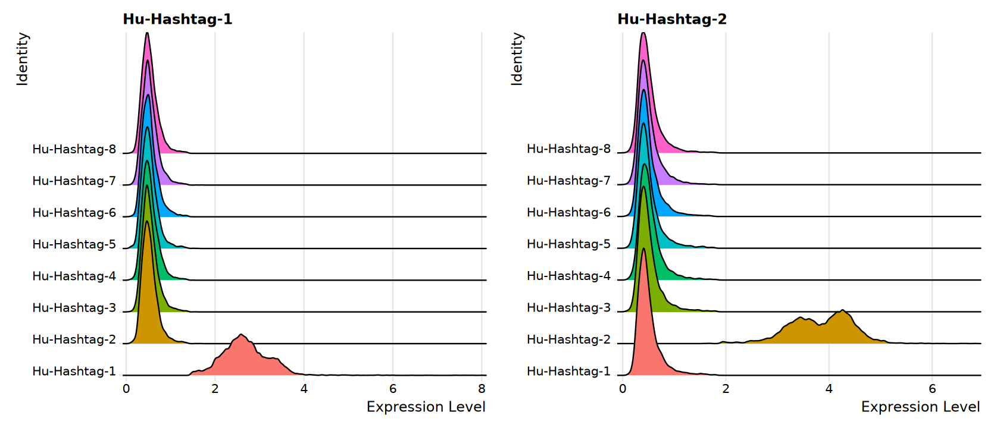

In [21]:
options(repr.plot.width = 14, repr.plot.height = 6)
RidgePlot(sc.temp, assay = "HTO", 
          features = Features(sc.comb[["HTO"]])[1:2],
          group.by = "HTO_maxID", ncol = 2)

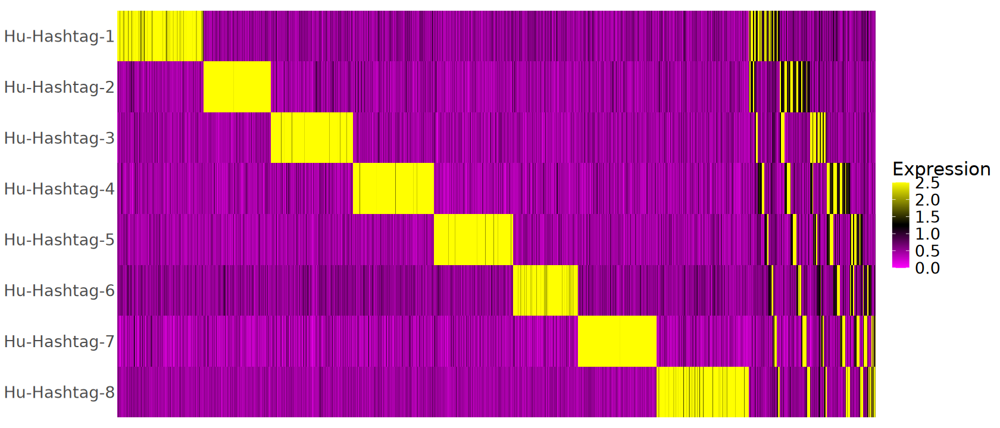

In [22]:
options(repr.plot.width = 14, repr.plot.height = 6)
HTOHeatmap(sc.temp, assay = "HTO") +
    theme(axis.text = element_text(size = 16),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [23]:
sc.temp <- sc.temp |>
    ScaleData(
        assay = "HTO", features = Features(sc.temp[["HTO"]]),
        verbose = FALSE) |>
    RunPCA(
        assay = "HTO", features = Features(sc.temp[["HTO"]]),
        approx = FALSE, verbose = FALSE) |>
    RunTSNE(
        assay = "HTO", dims = 1:8, perplexity = 100,
        verbose = FALSE)

In [24]:
sc.temp

An object of class Seurat 
28762 features across 39707 samples within 2 assays 
Active assay: HTO (8 features, 0 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, tsne

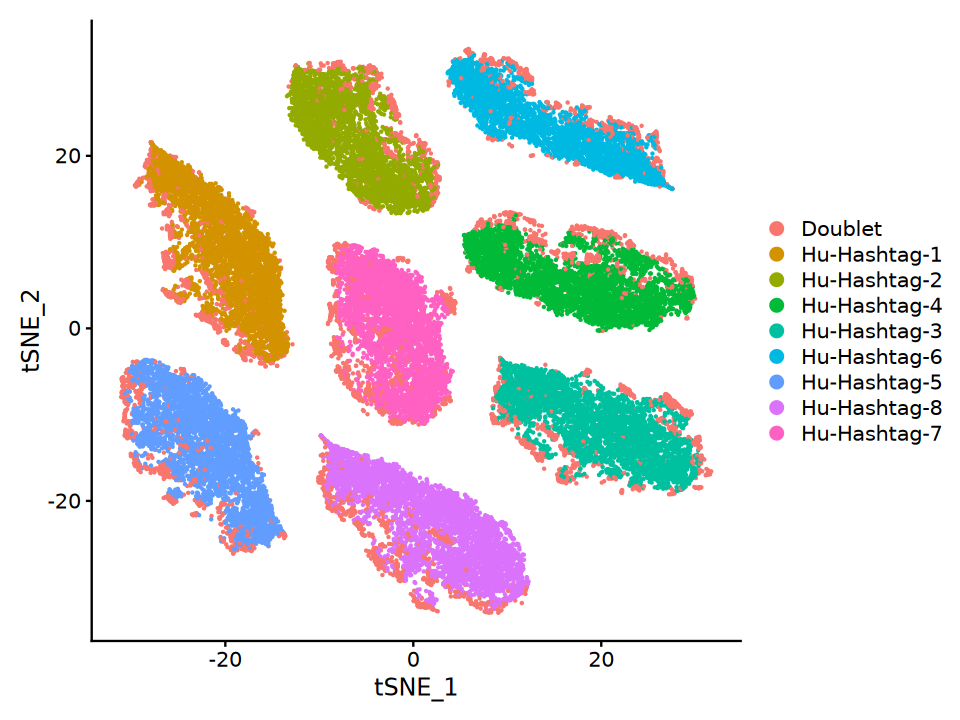

In [25]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp)

In [26]:
sc.comb$HTO_maxID <- sc.temp$HTO_maxID
sc.comb$HTO_classification.global <- sc.temp$HTO_classification.global

In [27]:
sc.comb <- subset(
    sc.comb, 
    sc.comb$HTO_classification.global == "Singlet")
sc.comb

An object of class Seurat 
28762 features across 33213 samples within 2 assays 
Active assay: RNA (28754 features, 0 variable features)
 4 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4
 1 other assay present: HTO

## 4). Visualizate Metrics

In [28]:
source("R/run_seurat_pipeline.R")

In [29]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


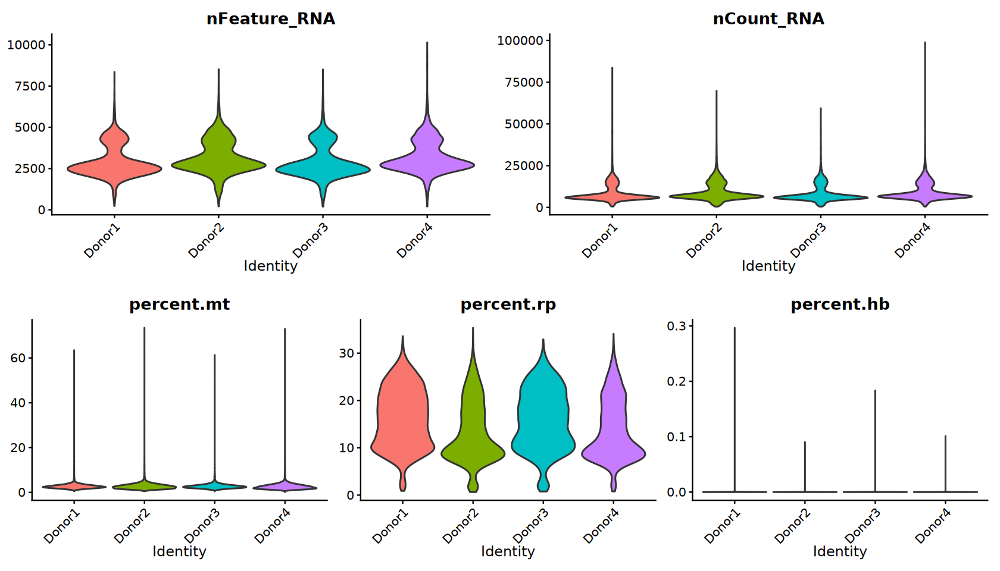

In [30]:
# Visualize QC metrics as a violin plot
p1 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("nFeature_RNA", "nCount_RNA"), 
    pt.size = 0, ncol = 2) & NoLegend()
p2 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("percent.mt", "percent.rp", "percent.hb"), 
    pt.size = 0, ncol = 3) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

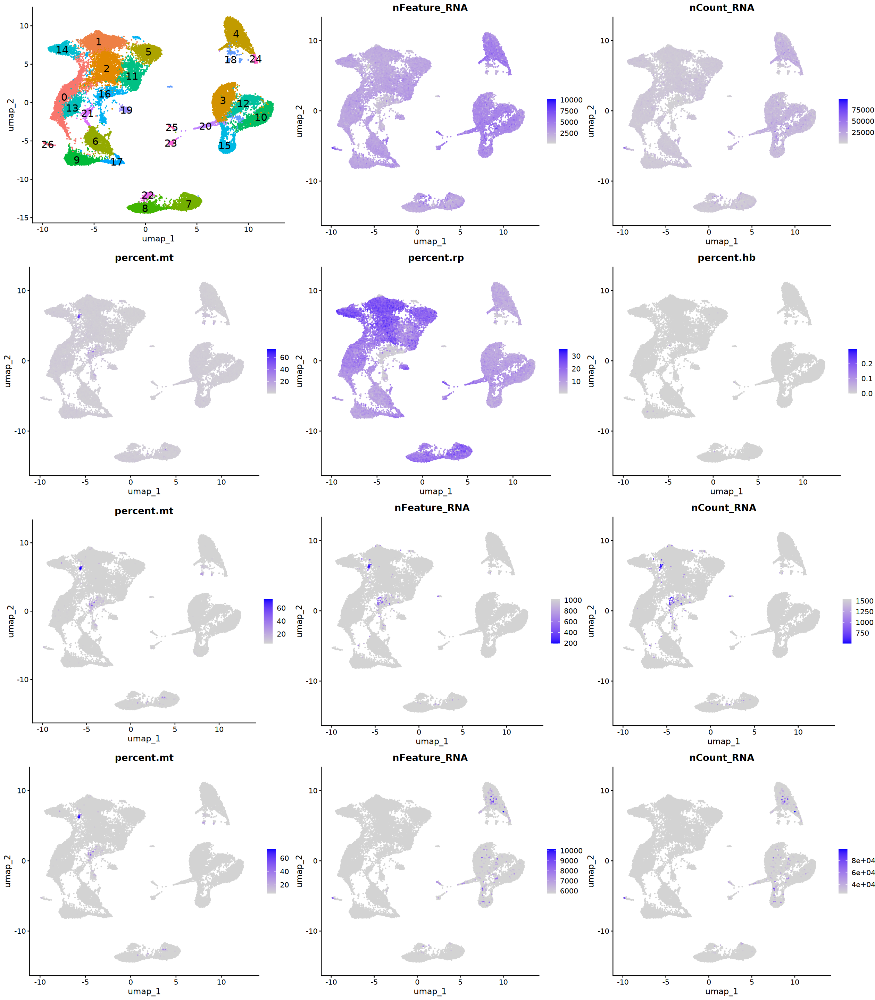

In [31]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p5 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4, p5), ncol = 3)

In [32]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA     nCount_RNA      percent.mt     
 Min.   :  195   Min.   :  507   Min.   : 0.1179  
 1st Qu.: 2407   1st Qu.: 5727   1st Qu.: 1.9382  
 Median : 2801   Median : 7049   Median : 2.4958  
 Mean   : 3070   Mean   : 9032   Mean   : 2.7278  
 3rd Qu.: 3760   3rd Qu.:11584   3rd Qu.: 3.1577  
 Max.   :10149   Max.   :98848   Max.   :73.4390  

In [33]:
source("R/calculate_mad_threshold.R")

In [34]:
nCount_threshold <- calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "both")
cat(sprintf("Counts: Lower: %d, Upper: %d\n", 
            nCount_threshold["lower_bound"],
            nCount_threshold["upper_bound"]))

nFeature_threshold <- calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "both")
cat(sprintf("Features: Lower: %d, Upper: %d\n", 
            nFeature_threshold["lower_bound"], 
            nFeature_threshold["upper_bound"]))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 3, sides = "upper")))

Counts: Lower: 2167, Upper: 22929
Features: Lower: 1200, Upper: 6538
Mitochondrial: Upper: 7


## 5). Filtering Low-quality Cells

In [35]:
sc.comb <- subset(
    sc.comb, 
    subset = nFeature_RNA > 500 & 
        nCount_RNA > 1000 & nCount_RNA < 30000 & 
        percent.mt < 10 & percent.hb < 1)
sc.comb

An object of class Seurat 
28762 features across 32860 samples within 2 assays 
Active assay: RNA (28754 features, 0 variable features)
 4 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4
 1 other assay present: HTO

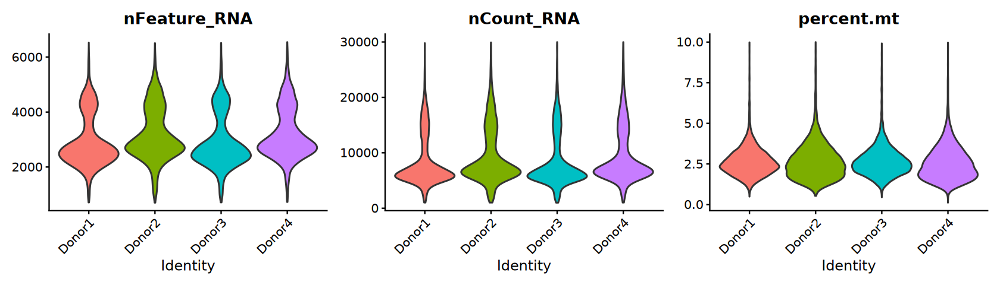

In [36]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.comb, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

## 6). Evaluating Noise

### a). Cell cycle effect

In [37]:
calculate_cell_cycle_score <- function(
    obj, species = c("human", "mouse")) {

    species <- match.arg(species)

    cc_s <- switch(
        species,
        "human" = cc.genes$s.genes,
        "mouse" = stringr::str_to_title(cc.genes$s.genes),
        tolower(cc.genes$s.genes))
    
    cc_g2m <- switch(
        species,
        "human" = cc.genes$g2m.genes,
        "mouse" = stringr::str_to_title(cc.genes$g2m.genes),
        tolower(cc.genes$g2m.genes))
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        CellCycleScoring(s.features = cc_s, g2m.features = cc_g2m, 
                         set.ident = FALSE)

    return(obj)
}

In [38]:
sc.comb <- calculate_cell_cycle_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

In [39]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")

In [40]:
calculate_dissociation_score <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)

    diss_genes <- switch(
        species,
        "human" = toupper(dissociation_genes),
        "mouse" = dissociation_genes,
        tolower(dissociation_genes)
    )
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        AddModuleScore(name = "Dissociation.Score", 
                       features = list(dissociationGenes = diss_genes))
    obj@meta.data <- obj@meta.data |> 
        dplyr::rename("Dis.Score" = "Dissociation.Score1")
    
    return(obj)
}

In [41]:
sc.comb <- calculate_dissociation_score(sc.comb, species = "human")

Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”


### c). Batch effect

In [42]:
sc.temp <- run_seurat_pipeline(sc.comb, ndim = 20)

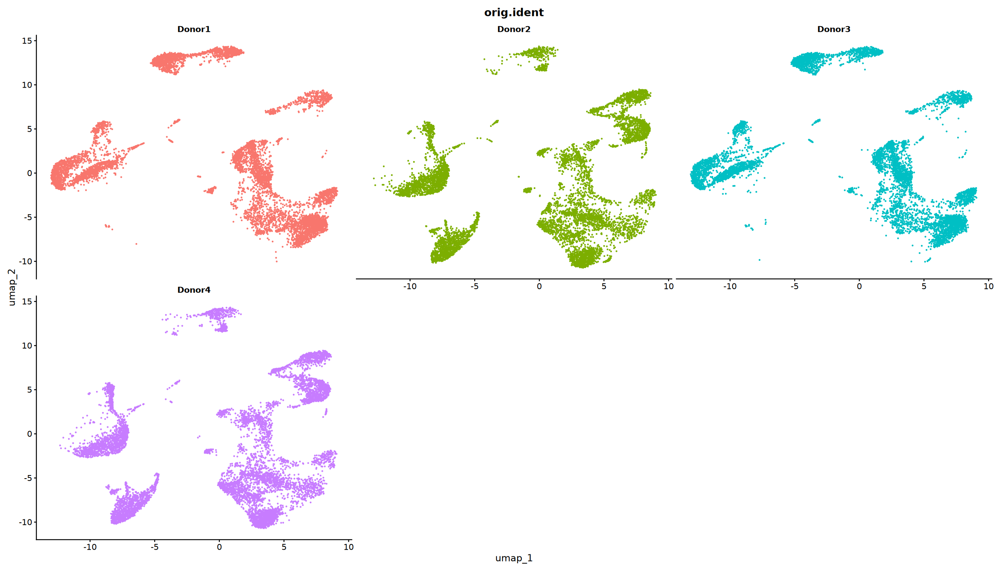

In [43]:
options(repr.plot.width = 21, repr.plot.height = 12)
DimPlot(sc.temp, reduction = "umap", group.by = "orig.ident", 
        split.by = "orig.ident", ncol = 3) & NoLegend()

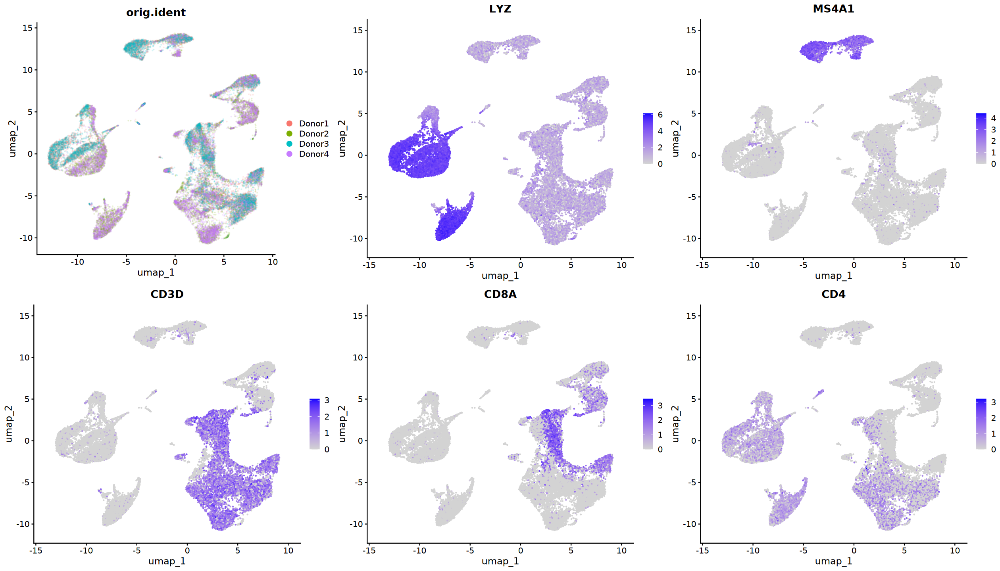

In [44]:
geneset <- c("LYZ", "MS4A1", "CD3D", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident",
    pt.size = 0.1, alpha = 0.1, label = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

# 3. Initial Assessment

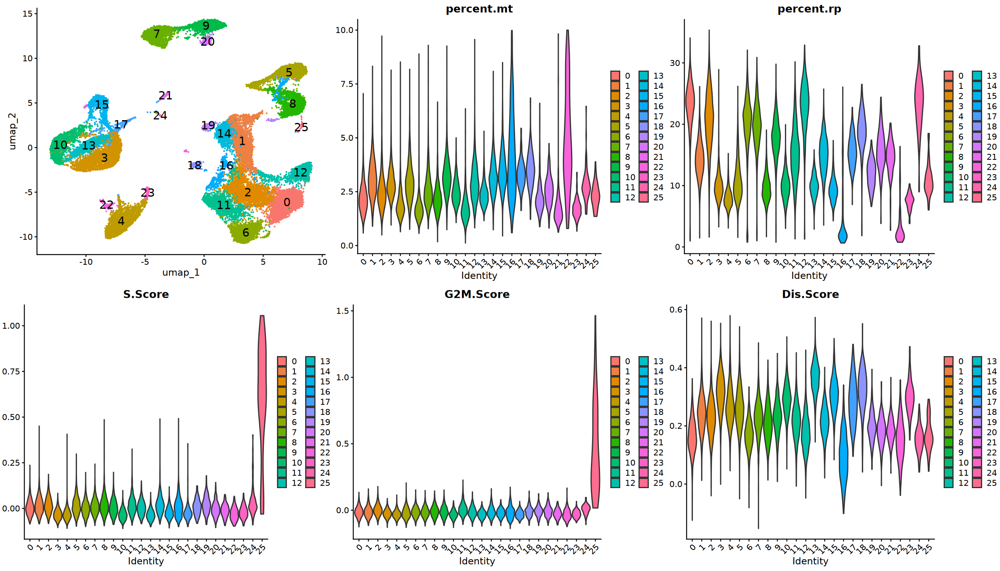

In [45]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

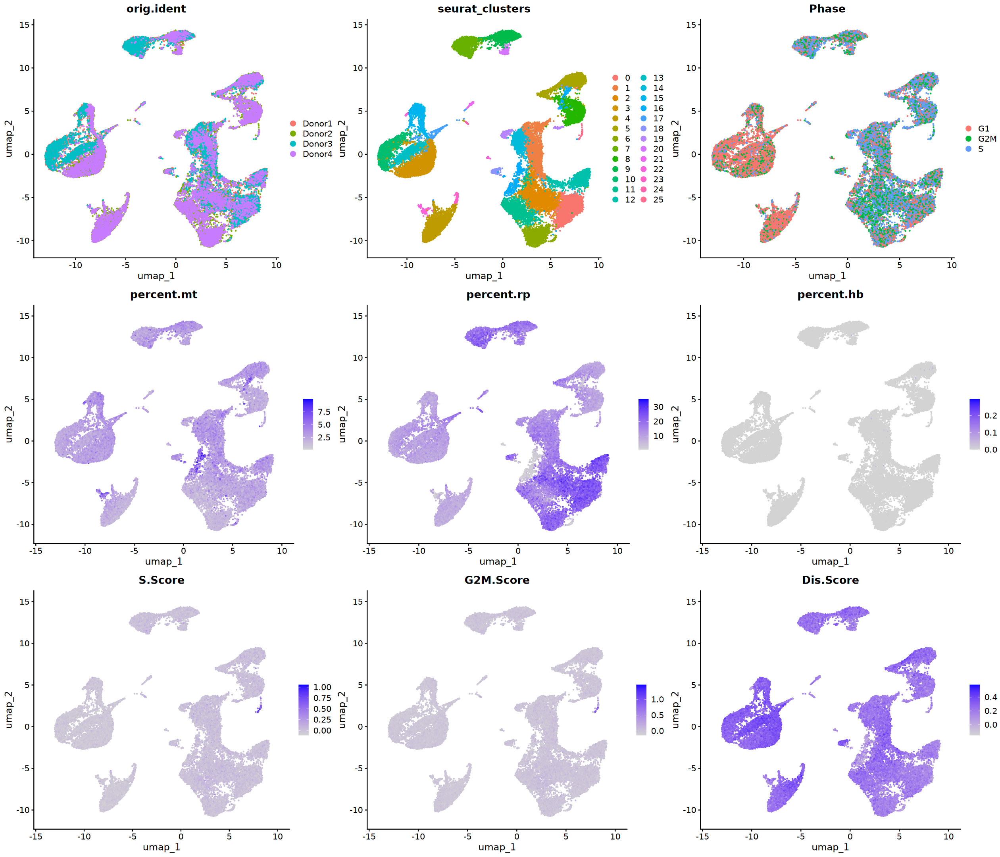

In [46]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

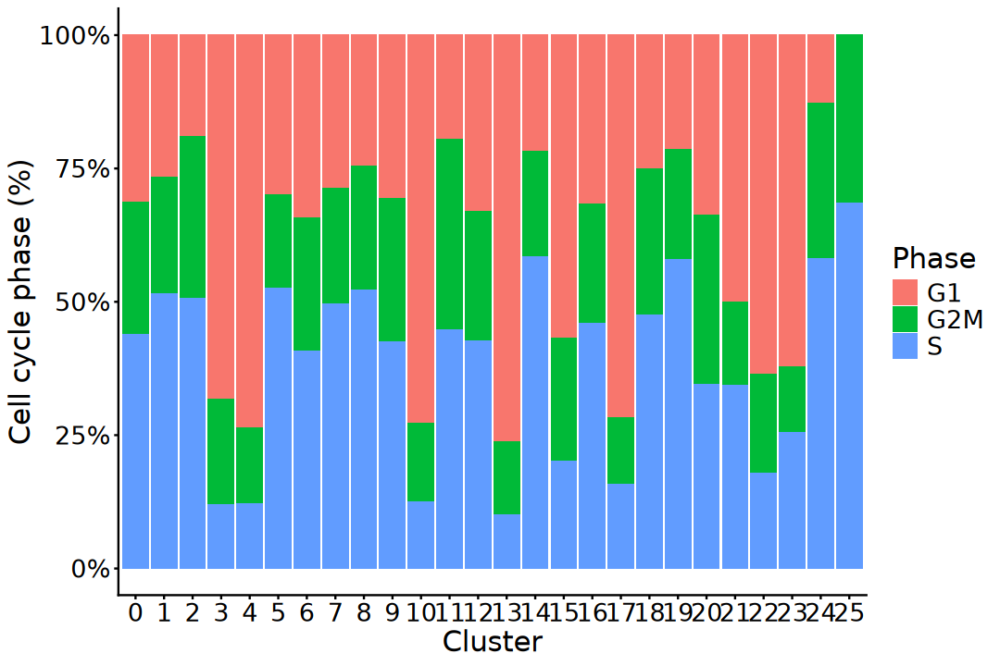

In [47]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [48]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

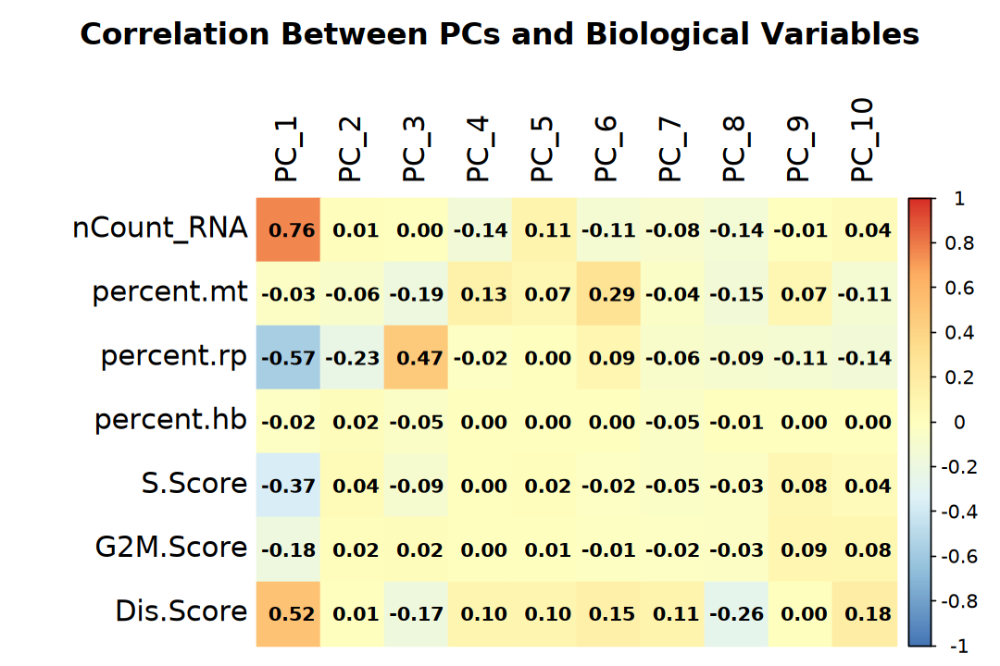

In [49]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-1, 1),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [50]:
sc.comb

An object of class Seurat 
28762 features across 32860 samples within 2 assays 
Active assay: RNA (28754 features, 0 variable features)
 8 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4
 1 other assay present: HTO

## 1). LogNormalize

In [51]:
sc.comb <- NormalizeData(sc.comb, verbose = FALSE)

In [52]:
sc.comb <- FindVariableFeatures(
    sc.comb, nfeatures = 3000, verbose = FALSE)

In [53]:
sc.temp <- ScaleData(
    sc.comb, vars.to.regress = "percent.mt", 
    verbose = FALSE)
sc.temp

An object of class Seurat 
28762 features across 32860 samples within 2 assays 
Active assay: RNA (28754 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: HTO

In [54]:
source("R/scale_data_chunked.R")

In [55]:
sc.comb <- scale_data_chunked(
    sc.comb, features = Features(sc.comb), 
    vars.to.regress = "percent.mt")
sc.comb

An object of class Seurat 
28762 features across 32860 samples within 2 assays 
Active assay: RNA (28754 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: HTO

In [56]:
scaledata1 <- LayerData(sc.temp, assay = "RNA", layer = "scale.data")
scaledata2 <- LayerData(sc.comb, assay = "RNA", layer = "scale.data")

In [57]:
identical(scaledata1, scaledata2[rownames(scaledata1), ]) && 
    all(scaledata1 == scaledata2[rownames(scaledata1), ])

[1] TRUE

## 2). SCTransform

In [58]:
sc.comb <- SCTransform(
    sc.comb, vars.to.regress = "percent.mt", 
    verbose = FALSE)
sc.comb

An object of class Seurat 
54560 features across 32860 samples within 3 assays 
Active assay: SCT (25798 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 2 other assays present: RNA, HTO

In [59]:
DefaultAssay(sc.comb) <- "RNA"
sc.comb

An object of class Seurat 
54560 features across 32860 samples within 3 assays 
Active assay: RNA (28754 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 2 other assays present: HTO, SCT

In [60]:
qs2::qs_save(sc.comb, file.path(
    data_dir, "result", "s4_normalization_seurat_V5.qs2"))

# 5. Linear Dimensionality Reduction

In [61]:
sc.comb <- RunPCA(sc.comb, npcs = 50, verbose = FALSE)

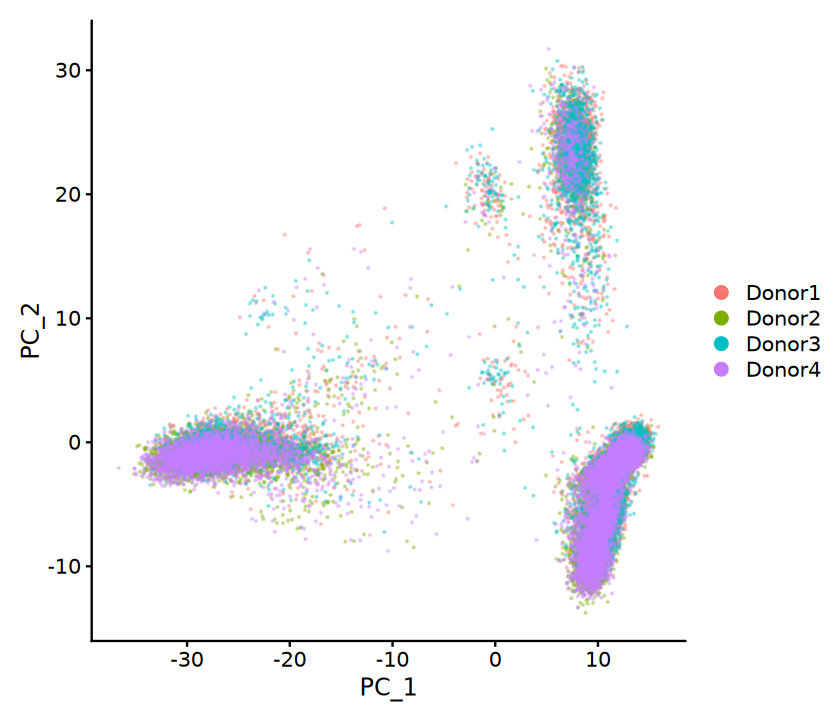

In [62]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "pca", alpha = 0.3)

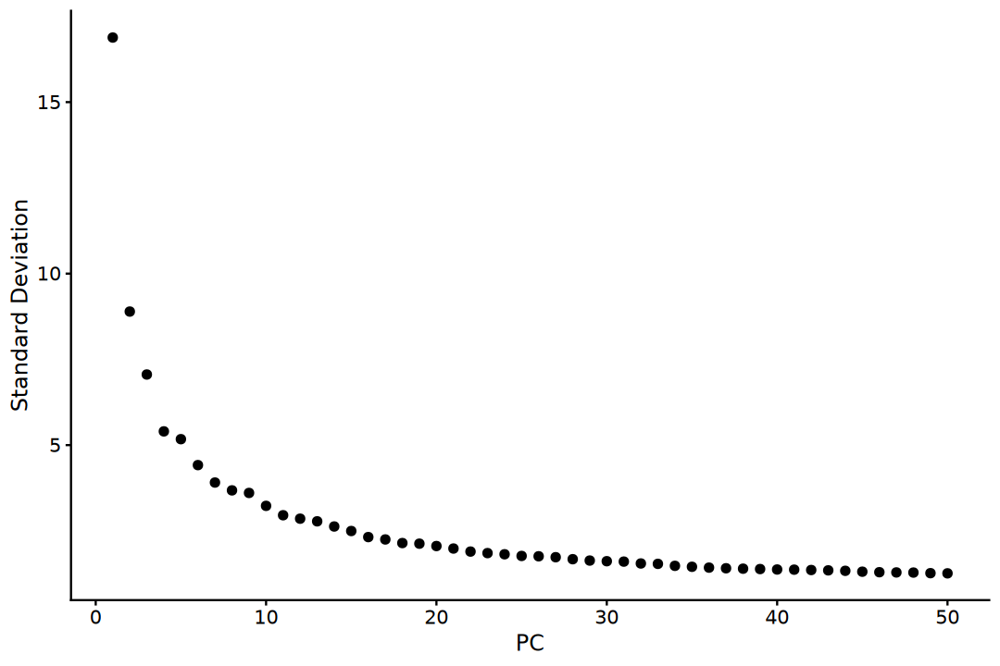

In [63]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(sc.comb, ndims = 50)

In [64]:
# Estimating PCA dimensionality
pca_var <- sc.comb@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 21


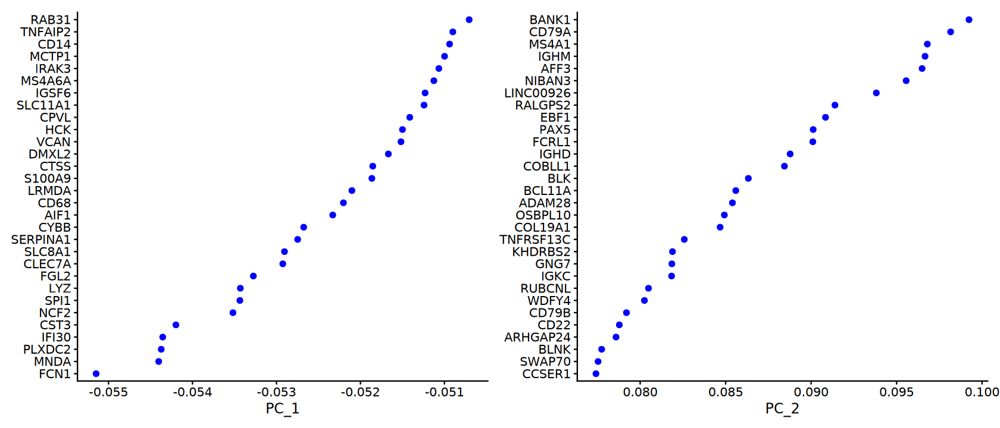

In [65]:
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(sc.comb, dims = 1:2, reduction = "pca", ncol = 2)

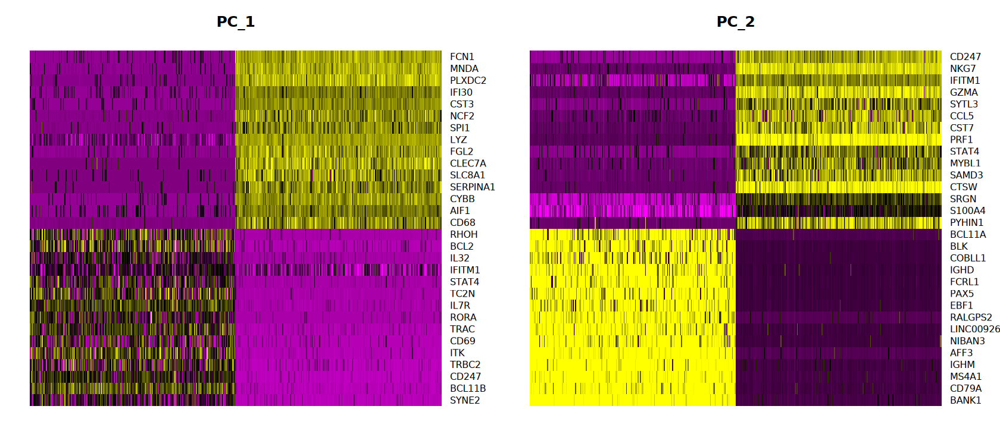

In [66]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(sc.comb, dims = 1:2, cells = 500, balanced = TRUE)

In [67]:
source("R/compare_npcs_clustering.R")

In [68]:
plots <- compare_npcs_clustering(
    sc.comb, reduction = "pca", method = "umap")

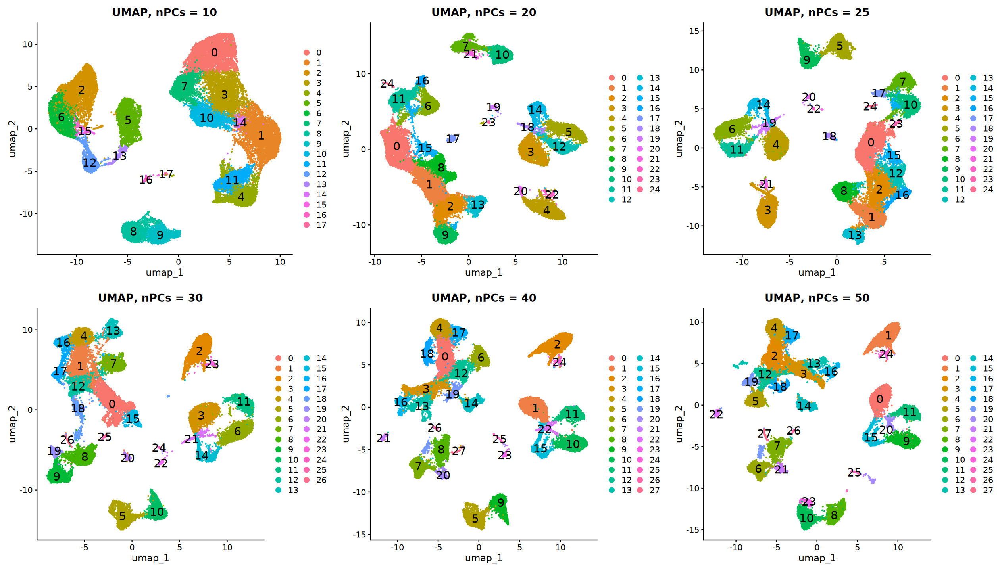

In [69]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plots, ncol = 3)

In [70]:
nPCs <- 30

# 6. Integration (Skip)

In [71]:
sc.comb <- JoinLayers(sc.comb)
sc.comb

An object of class Seurat 
54560 features across 32860 samples within 3 assays 
Active assay: RNA (28754 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 2 other assays present: HTO, SCT
 1 dimensional reduction calculated: pca

# 7. Neighborhood Graph Construction

In [72]:
sc.comb <- FindNeighbors(
    sc.comb, k.param = 20, reduction = "pca", 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [73]:
sc.comb <- RunUMAP(
    sc.comb, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

In [74]:
sc.comb <- RunTSNE(
    sc.comb, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

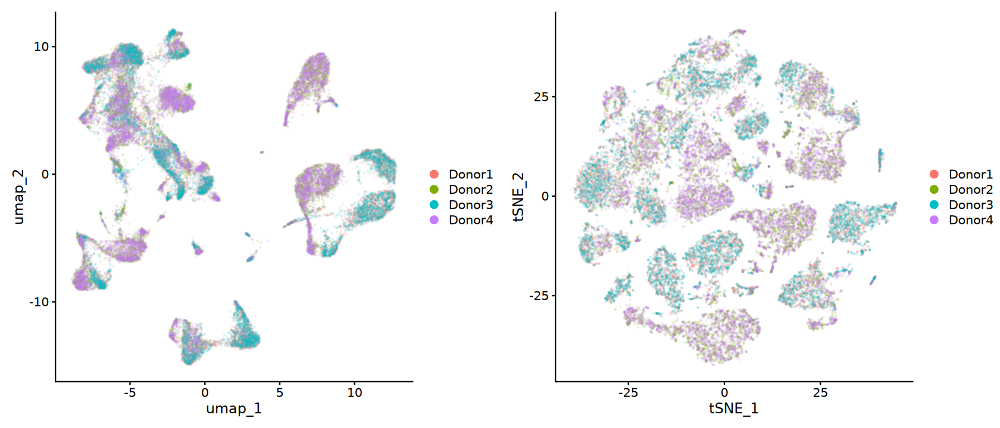

In [75]:
p1 <- DimPlot(
    sc.comb, reduction = "umap", pt.size = 0.1, alpha = 0.1)
p2 <- DimPlot(
    sc.comb, reduction = "tsne", pt.size = 0.1, alpha = 0.1)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [76]:
source("R/scan_clustering_resolution.R")

In [77]:
cluster_list <- scan_clustering_resolution(
    sc.comb, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1))

Registered S3 method overwritten by 'pROC':
  method   from            
  plot.roc spatstat.explore



In [78]:
metrics_df <- cluster_list$metrics |>
    mutate(accuracy = round(accuracy * 100, 2), 
           f1 = round(f1 * 100, 2),
           silhouette = round(silhouette * 100, 2),
           modularity = round(modularity * 100, 2))
metrics_df

,resolution,n_cluster,accuracy,f1,silhouette,modularity
,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
res_0.1,0.1,15,71.51,80.58,15.80,86.72
res_0.2,0.2,19,66.92,70.53,13.40,90.33
res_0.3,0.3,23,63.12,64.30,14.97,90.98
res_0.4,0.4,24,57.37,66.07,15.47,91.07
res_0.5,0.5,27,55.59,69.68,15.86,91.52
res_0.6,0.6,30,52.65,44.07,16.21,91.76
res_0.7,0.7,29,48.57,41.01,15.90,91.66
res_0.8,0.8,31,50.68,41.24,16.28,91.72
res_0.9,0.9,32,49.08,40.36,16.30,91.71


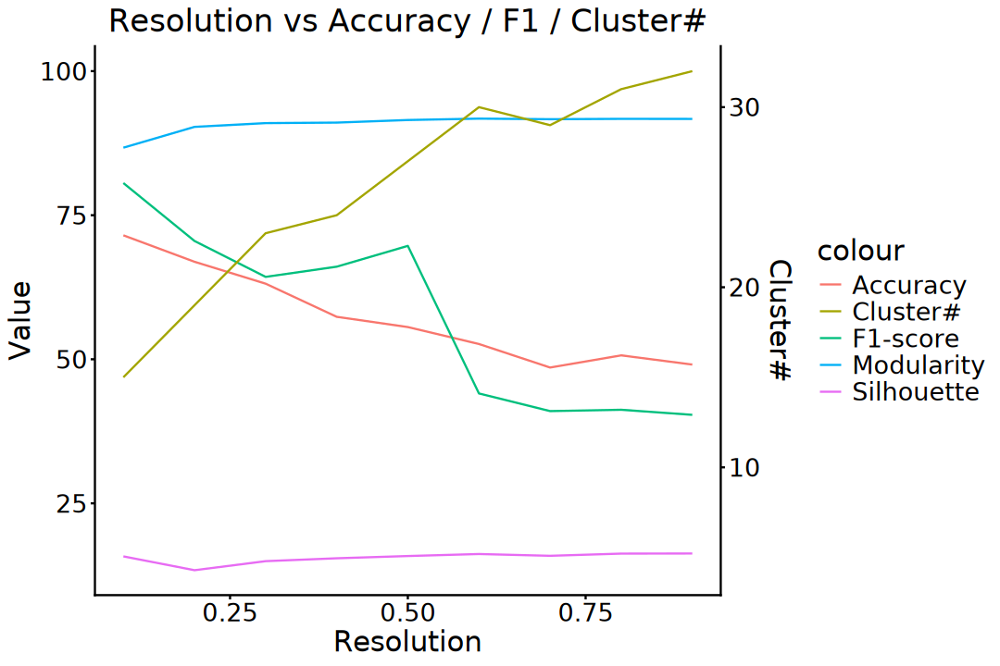

In [79]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(metrics_df, aes(x = resolution)) +
    geom_line(aes(y = accuracy, color = "Accuracy")) +
    geom_line(aes(y = f1, color = "F1-score")) +
    geom_line(aes(y = silhouette, color = "Silhouette")) +
    geom_line(aes(y = modularity, color = "Modularity")) +
    geom_line(aes(y = n_cluster/ max(n_cluster)*100, 
                  color = "Cluster#")) +
    scale_y_continuous(
        name = "Value", 
        sec.axis = sec_axis(
            ~./100*max(metrics_df$n_cluster), name = "Cluster#")) +
    ggtitle("Resolution vs Accuracy / F1 / Cluster#") + 
    labs(x = "Resolution") +
    theme_classic() +
    theme(plot.title =  element_text(size = 20, hjust = 0.5),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

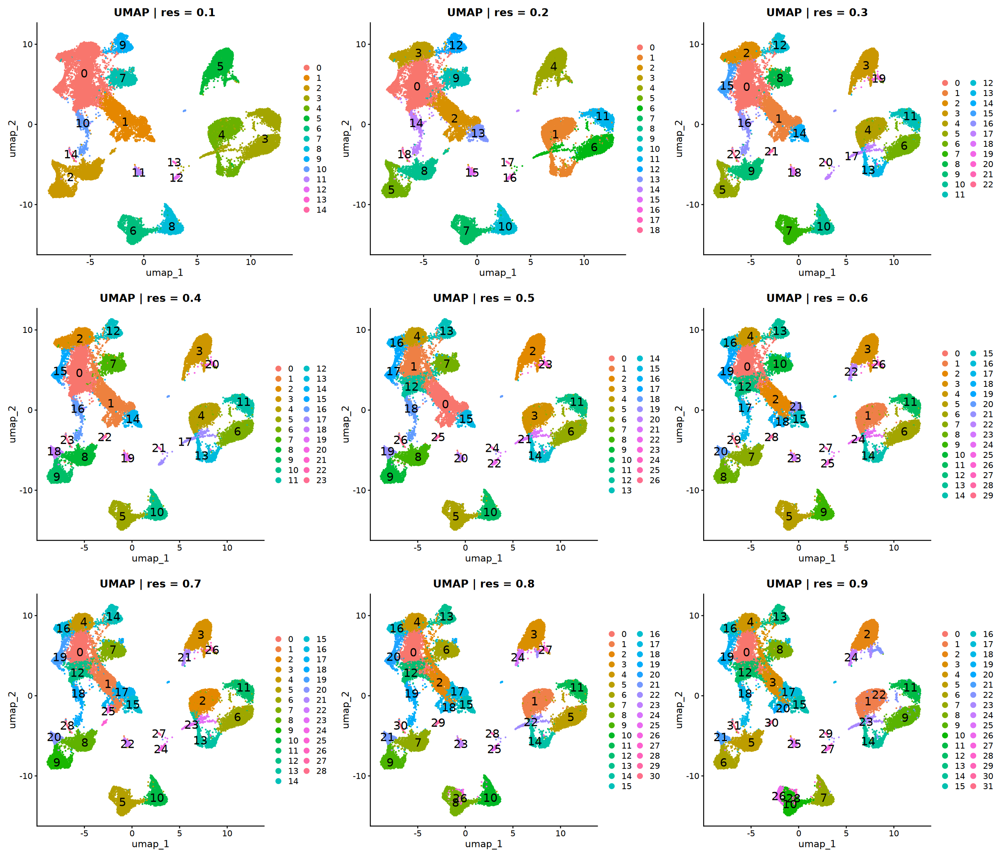

In [80]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

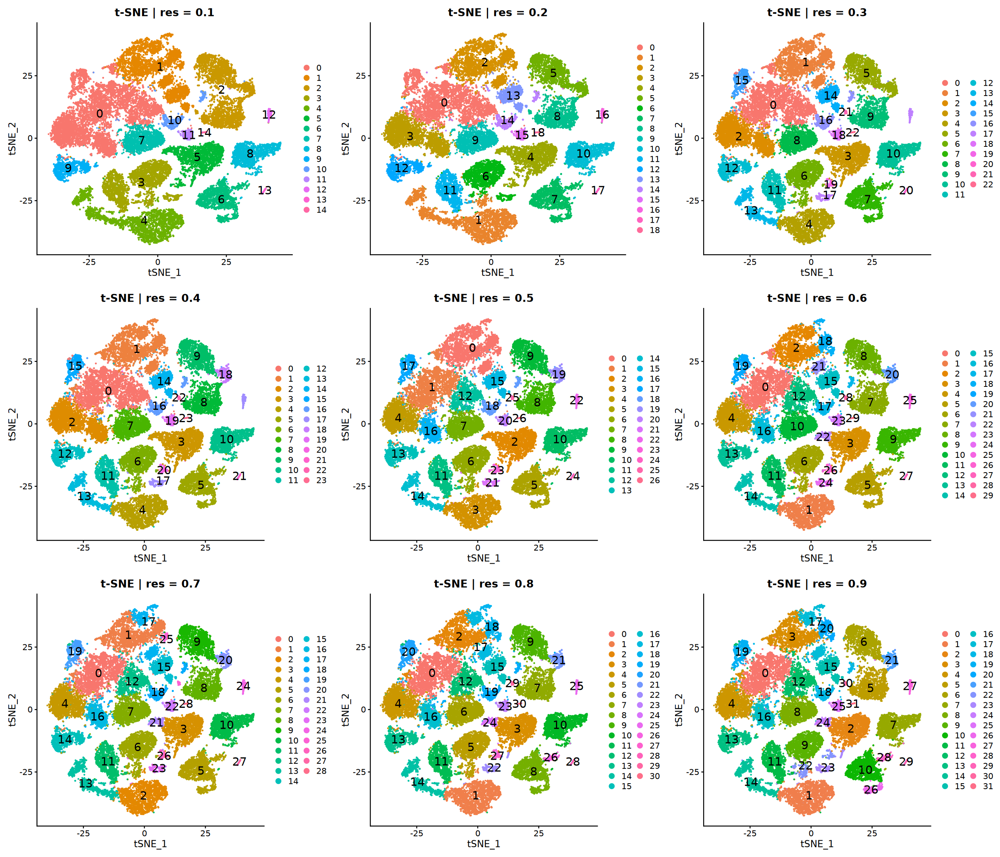

In [81]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$tsne, ncol = 3)

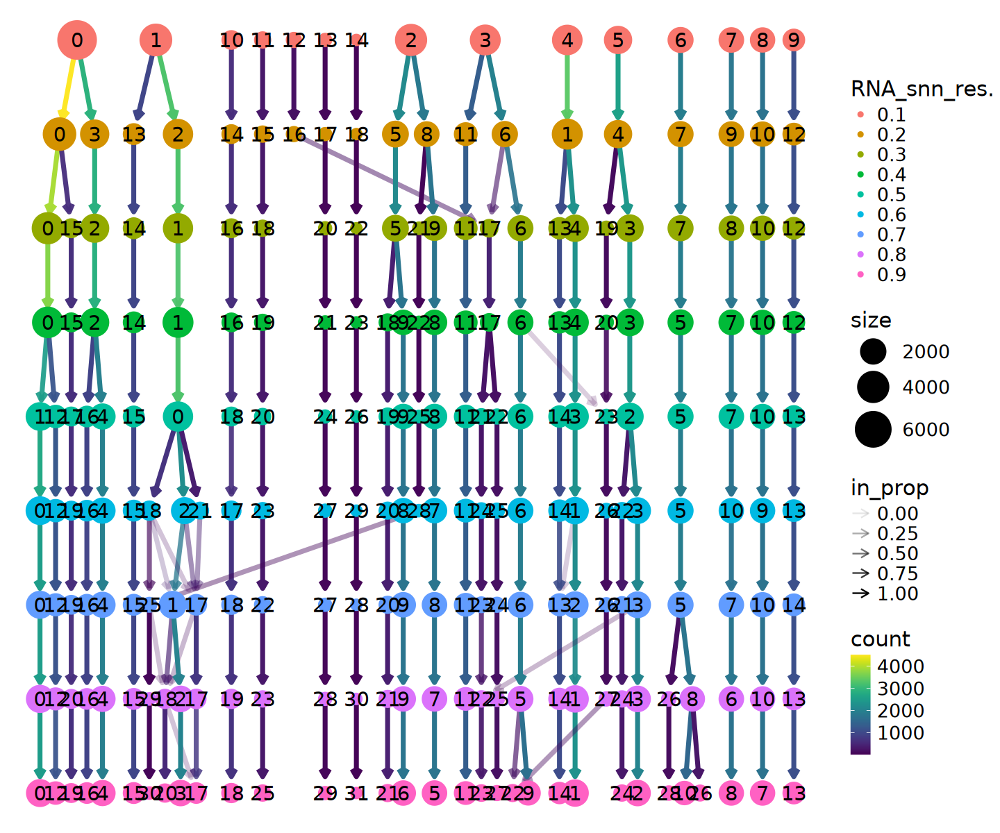

In [82]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [83]:
sc.comb <- FindClusters(
    sc.comb, resolution = 0.5, verbose = FALSE)

In [84]:
# n.neighbors 5 ~ 50, 30
# min.dist 0.001 ~ 0.5, 0.3
plot_umap_params <- function(obj, dims = 10, nn = 30, md = 0.3) {    
    RunUMAP(obj, dims = 1:dims, reduction = "pca", 
            n.neighbors = nn, min.dist = md, verbose = FALSE) |>
    DimPlot(reduction = "umap", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("n.neighbors = ", nn, "\nmin.dist = ", md))
}

In [85]:
p1 <- lapply(
    c(10, 30, 50), plot_umap_params, 
    obj = sc.comb, dims = nPCs, md = 0.3)
p2 <- lapply(
    c(0.01, 0.3, 0.5), plot_umap_params, 
    obj = sc.comb, dims = nPCs, nn = 30)

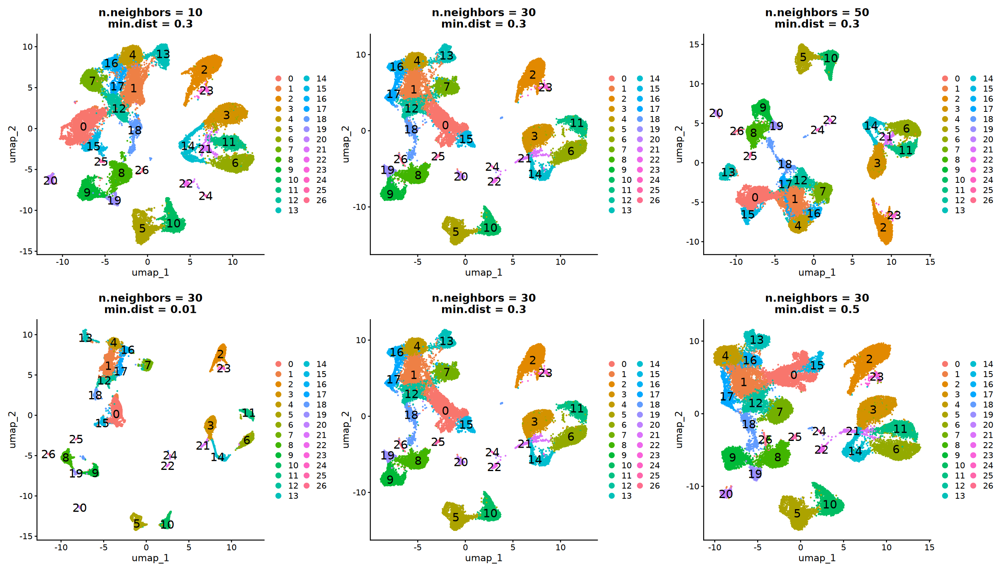

In [86]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plot_grid(plotlist = p1, ncol = 3),
          plot_grid(plotlist = p2, ncol = 3), ncol = 1)

In [87]:
# perplexity 5 ~ 50, 30
plot_tsne_params <- function(obj, dims = 10, perplexity = 30) {    
    RunTSNE(obj, dims = 1:dims, reduction = "pca", 
            perplexity = perplexity, verbose = FALSE) |>
    DimPlot(reduction = "tsne", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("perplexity = ", perplexity))
}

In [88]:
p1 <- lapply(
    c(10, 30, 50), plot_tsne_params, 
    obj = sc.comb, dims = nPCs)

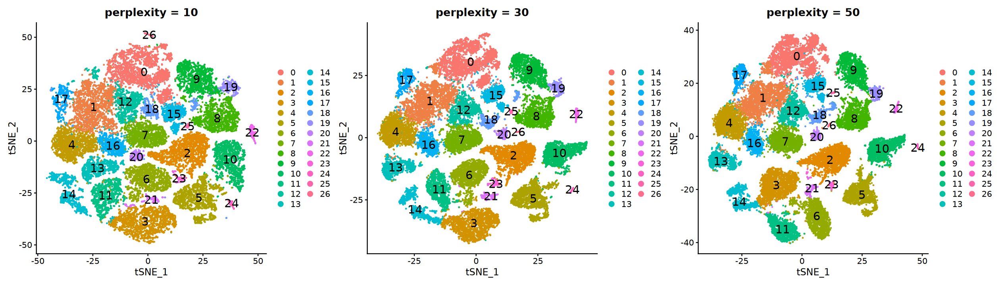

In [89]:
options(repr.plot.width = 21, repr.plot.height = 6)
# plot_grid(plotlist = p1, ncol = 3)
p1[[1]] + p1[[2]] + p1[[3]]

In [90]:
sc.comb <- RunUMAP(
    sc.comb, dims = 1:nPCs, reduction = "pca",
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

In [91]:
sc.comb <- RunTSNE(
    sc.comb, dims = 1:nPCs, reduction = "pca", 
    perplexity = 30, verbose = FALSE)

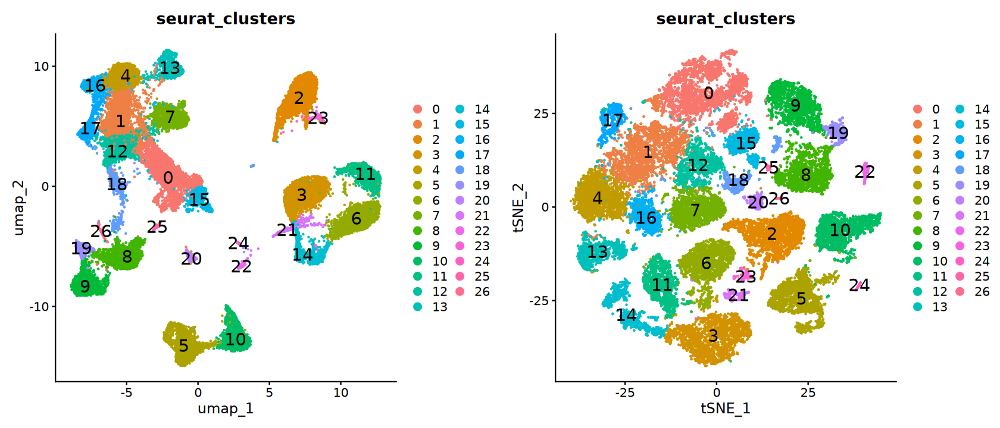

In [92]:
p1 <- DimPlot(
    sc.comb, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.comb, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

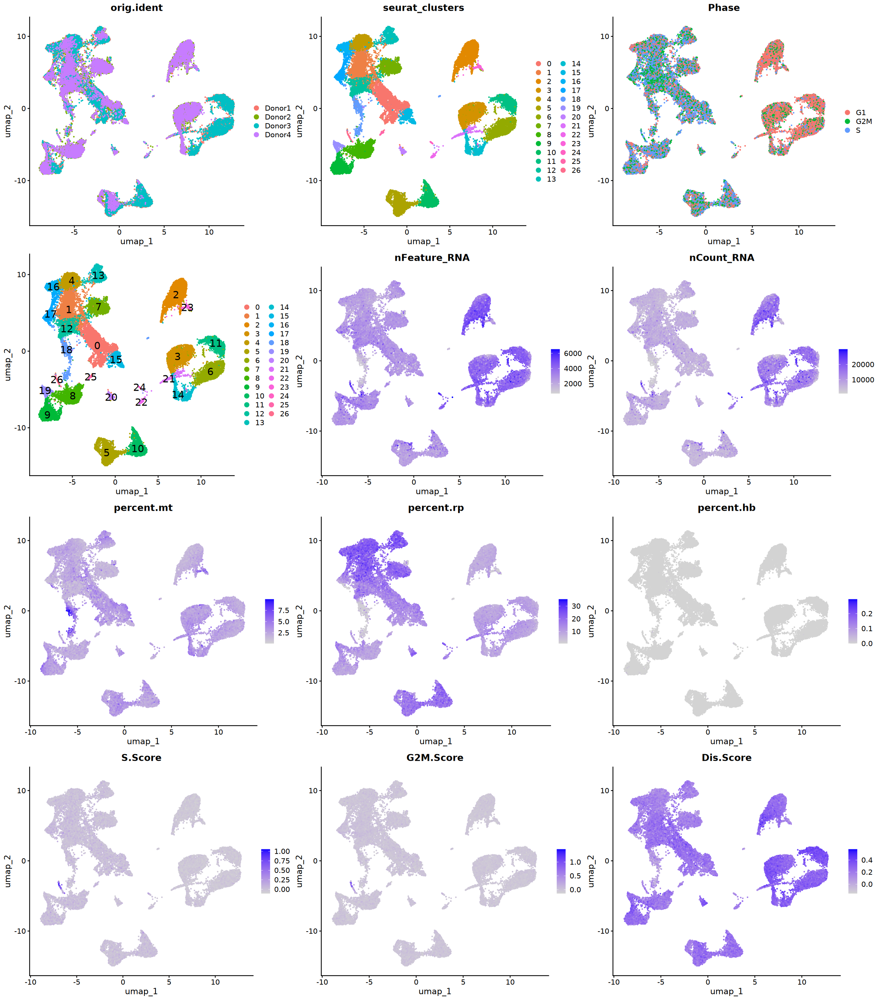

In [93]:
p1 <- DimPlot(
    sc.comb, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- DimPlot(
    sc.comb, reduction = "umap", combine = FALSE,
    label = TRUE, label.size = 6)
p3 <- FeaturePlot(
    sc.comb, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    sc.comb, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [94]:
sc.comb

An object of class Seurat 
54560 features across 32860 samples within 3 assays 
Active assay: RNA (28754 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 2 other assays present: HTO, SCT
 3 dimensional reductions calculated: pca, umap, tsne

# 10. Cluster Biomarkers

In [95]:
sc.markers <- FindAllMarkers(
    sc.comb, logfc.threshold = log2(1.2),
    min.pct = 0.25, verbose = FALSE)

In [96]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [97]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,⋯,17,18,19,20,21,22,23,24,25,26
length(gene),146,125,2208,1744,107,281,1768,240,378,256,⋯,113,16,300,241,1917,1897,480,2579,303,1100


In [98]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

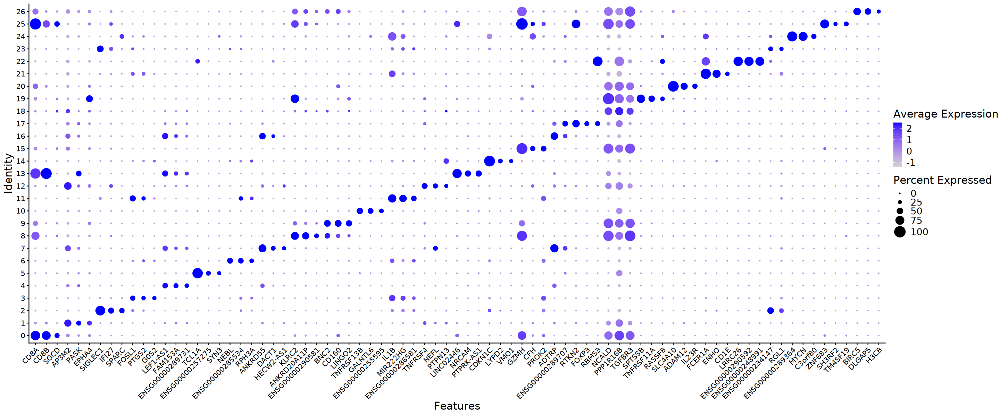

In [99]:
options(repr.plot.width = 24, repr.plot.height = 10)
DotPlot(sc.comb, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [100]:
plot_dir <- file.path(
    data_dir, "visualization", "p7.1_cluster_top10_genes")

if (!dir.exists(plot_dir)) {
    dir.create(plot_dir, recursive = TRUE)
}

In [101]:
for (index in seq(1:length(top10$gene))) {
    p1 <- VlnPlot(sc.comb, features = top10$gene[index])
    p2 <- FeaturePlot(
        sc.comb, reduction = "umap", features = top10$gene[index])
    p3 <- FeaturePlot(
        sc.comb, reduction = "tsne", features = top10$gene[index])
    pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
    file.path(plot_dir, paste0(
        "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
        ggsave(plot = pg, width = 9, height = 8)
}

In [102]:
ht <- DoHeatmap(sc.comb, features = top3$gene, 
                slot = "scale.data", size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

file.path(data_dir, "visualization", "p7.2_DEG_Top3_DoHeatmap.png") |>
    ggsave(plot = ht, width = 24, height = 16)

# 11. Cell-type Annotation

## a). Automatic

In [103]:
suppressPackageStartupMessages(library(SingleR))
suppressPackageStartupMessages(library(SingleCellExperiment))

In [104]:
ref_pbmc <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "matrix", "RNA_3P", "RNA") |>
    Read10X()

In [105]:
ref_metadata <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    select(celltype.l1, celltype.l2, celltype.l3)

In [106]:
ref_pbmc <- SingleCellExperiment(
    list(counts = ref_pbmc), 
    colData = ref_metadata)

ref_pbmc <- scuttle::logNormCounts(ref_pbmc)

ref_pbmc

class: SingleCellExperiment 
dim: 33538 161764 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(161764): L1_AAACCCAAGAAACTCA L1_AAACCCAAGACATACA ...
  E2L8_TTTGTTGGTTGGCTAT E2L8_TTTGTTGTCTCATGGA
colData names(4): celltype.l1 celltype.l2 celltype.l3 sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [107]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    sc.comb, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l2, 
            clusters = sc.comb$seurat_clusters,
            de.method = "wilcox")

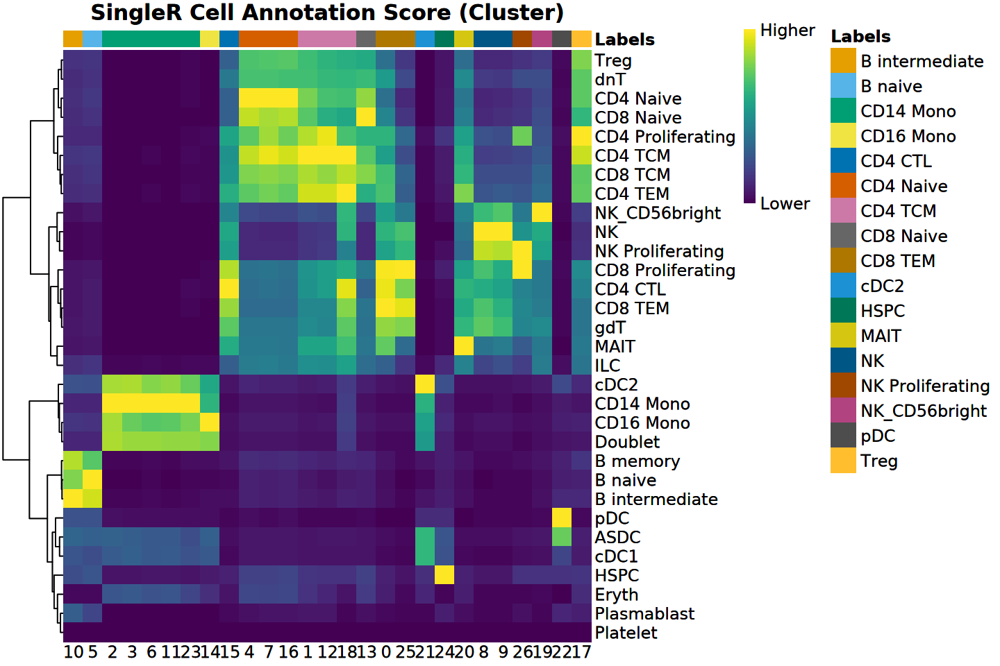

In [108]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [109]:
sc.comb$celltype.SingleR <- 
    celltype.SingleR$labels[sc.comb$seurat_clusters]

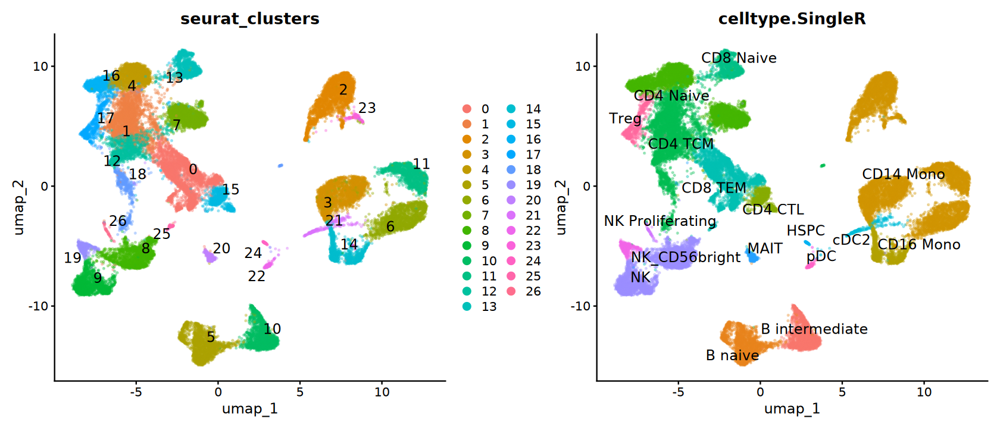

In [110]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

## b). Manual

In [111]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [112]:
gene_list |> cat(sep = "\n")

cluster_0: "CCL5", "CD8A", "CD8B", "GZMH", "DUSP2", "TRGC2", "GZMK", "SGCD", "MYO6", "LINC00944"
cluster_1: "IL7R", "CD28", "AQP3", "MAL", "AP3M2", "FAAH2", "ICOS", "PASK", "EPHA4", "TNFRSF25"
cluster_2: "SIGLEC1", "RNASE2", "SERPING1", "RETN", "ENSG00000234147", "IFI27", "SPARC", "STON2", "HESX1", "FPR3"
cluster_3: "VSTM1", "EGR1", "NRG1", "HBEGF", "ID1", "FOSL1", "TDRD9", "TNFRSF12A", "PTGS2", "G0S2"
cluster_4: "NELL2", "AK5", "EEIG1", "LINC01550", "CHRM3-AS2", "LEF1-AS1", "FAM153A", "EPHX2", "ENSG00000289731", "EPHA1-AS1"
cluster_5: "IGHD", "FCRL1", "TCL1A", "COL19A1", "PCDH9", "LINC02397", "KCNH8", "ENSG00000257275", "SCN3A", "SYN3"
cluster_6: "LGALS2", "RNF144B", "TMTC1", "OLIG1", "NEBL", "ENSG00000285534", "STEAP4", "RPH3A", "CACNA1D", "ADGRB3"
cluster_7: "TSHZ2", "ADTRP", "SLC40A1", "ANKRD55", "EDA", "DST", "DACT1", "NEFL", "NEXMIF", "HECW2-AS1"
cluster_8: "TRDC", "KLRC3", "KLRC2", "KIR3DL1", "ANKRD20A11P", "KIR2DL1", "KLRC1", "ENSG00000290581", "FASLG", "LDB2"
cluster_9: "SPON2

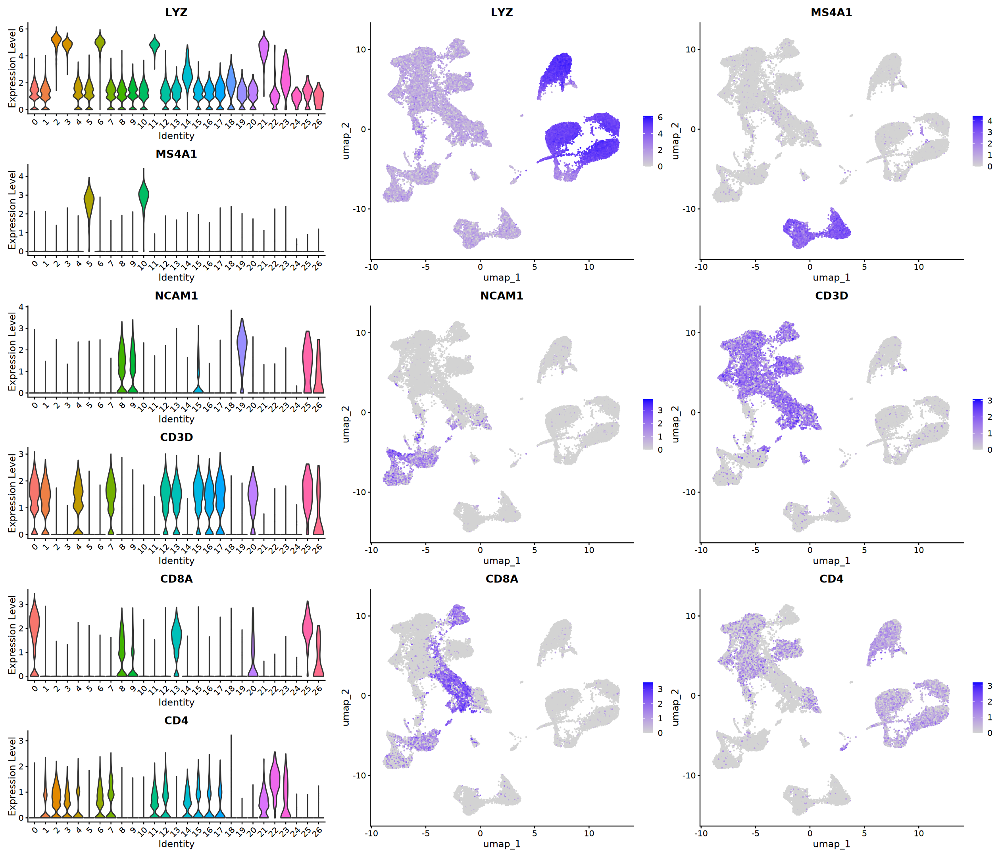

In [113]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    sc.comb, features = geneset, ncol = 1, pt.size = 0)
p2 <- FeaturePlot(
    sc.comb, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 2, rel_widths = c(1, 2))

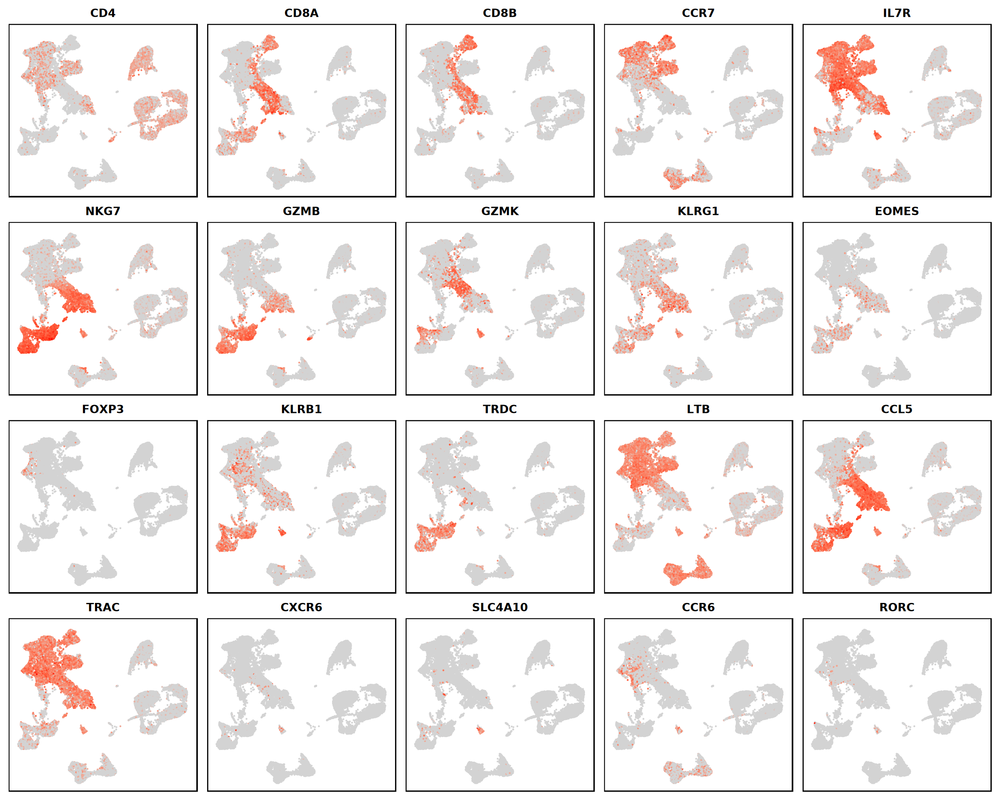

In [114]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5",
             "TRAC", "CXCR6", "SLC4A10", "CCR6", "RORC")

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(sc.comb, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

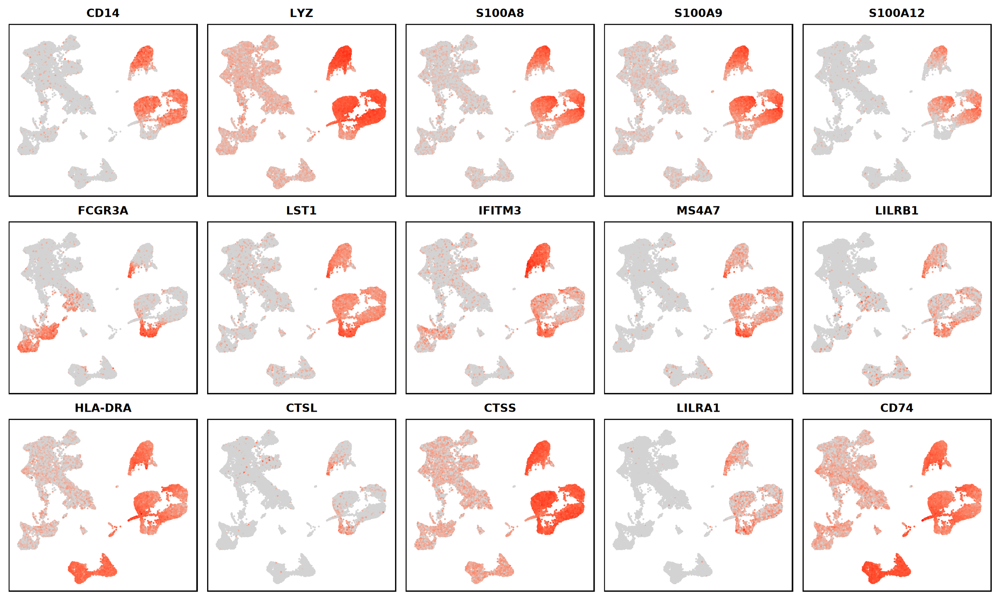

In [115]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(sc.comb, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

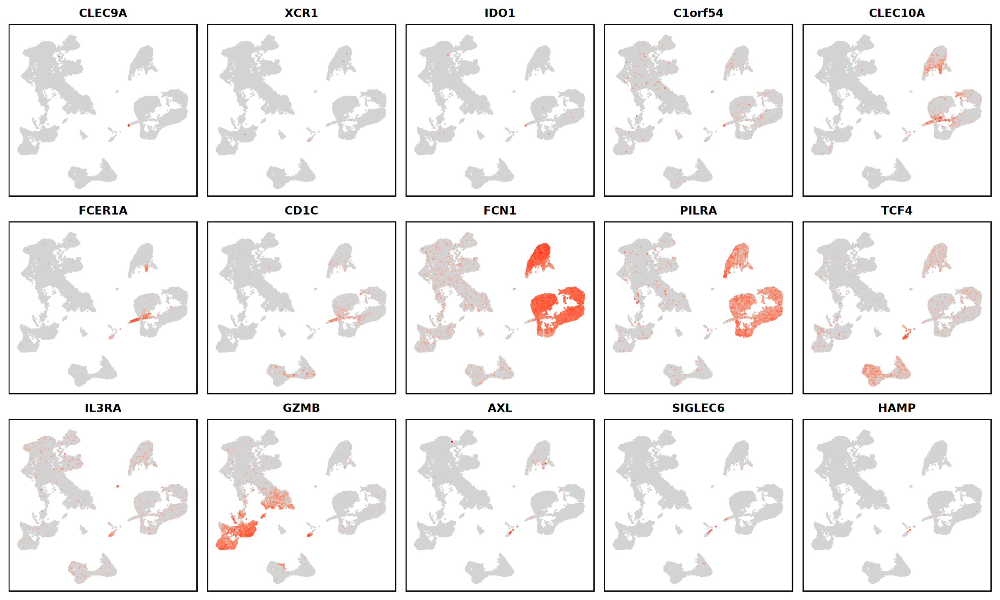

In [116]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "GZMB", "TCF4", "IL3RA", "CLEC4C"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CLEC10A", "FCER1A", "CD1C", "FCN1", "PILRA",
             "TCF4", "IL3RA", "GZMB",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(sc.comb, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

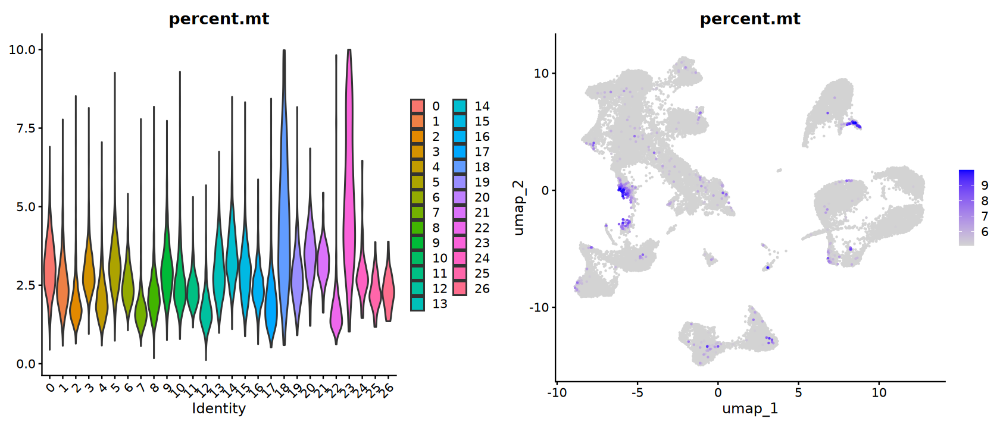

In [117]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <- VlnPlot(
    sc.comb, features = "percent.mt", pt.size = 0)
p2 <- FeaturePlot(
    sc.comb, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE)

plot_grid(plotlist = c(p1, p2), ncol = 2)

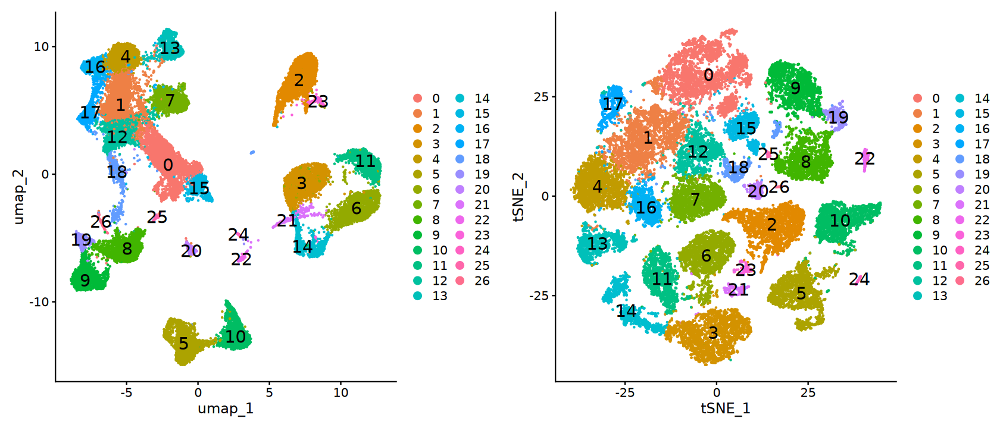

In [118]:
p1 <- DimPlot(
    sc.comb, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.comb, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [119]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Cytotoxic CD8 T", "1" = "Activated CD4 T", "2" = "Classical Monocytes",
    "3" = "Classical Monocytes", "4" = "Naïve CD4 T", "5" = "Naïve B",
    "6" = "Classical Monocytes", "7" = "Activated CD4 T", "8" = "NK Cells",
    "9" = "NK Cells", "10" = "Plasmablast", "11" = "Classical Monocytes",
    "12" = "Activated CD4 T", "13" = "Naïve CD8 T", "14" = "Non-classical Monocytes",
    "15" = "Activated CD4 T", "16" = "Naïve CD4 T", "17" = "Treg",
    "18" = "Activated CD4 T", "19" = "NK Cells", "20" = "MAIT",
    "21" = "cDC2", "22" = "pDC", "23" = "Classical Monocytes",
    "24" = "HSPC", "25" = "Cytotoxic CD8 T", "26" = "Proliferating")

In [120]:
# Cell annotation with ChatGPT assistance
group2celltype <- c(
    "0" = "T", "1" = "T", "2" = "Myeloids",
    "3" = "Myeloids", "4" = "T", "5" = "B",
    "6" = "Myeloids", "7" = "T", "8" = "NK",
    "9" = "NK", "10" = "B", "11" = "Myeloids",
    "12" = "T", "13" = "T", "14" = "Myeloids",
    "15" = "T", "16" = "T", "17" = "T",
    "18" = "T", "19" = "NK", "20" = "T",
    "21" = "Myeloids", "22" = "Myeloids", "23" = "Myeloids",
    "24" = "HSPC", "25" = "T", "26" = "Proliferating")

In [121]:
sc.comb@meta.data$celltype <- 
    cluster2celltype[as.character(sc.comb$seurat_clusters)]
sc.comb@meta.data$grouptype <- 
    group2celltype[as.character(sc.comb$seurat_clusters)]

sc.comb <- RenameIdents(sc.comb, cluster2celltype)

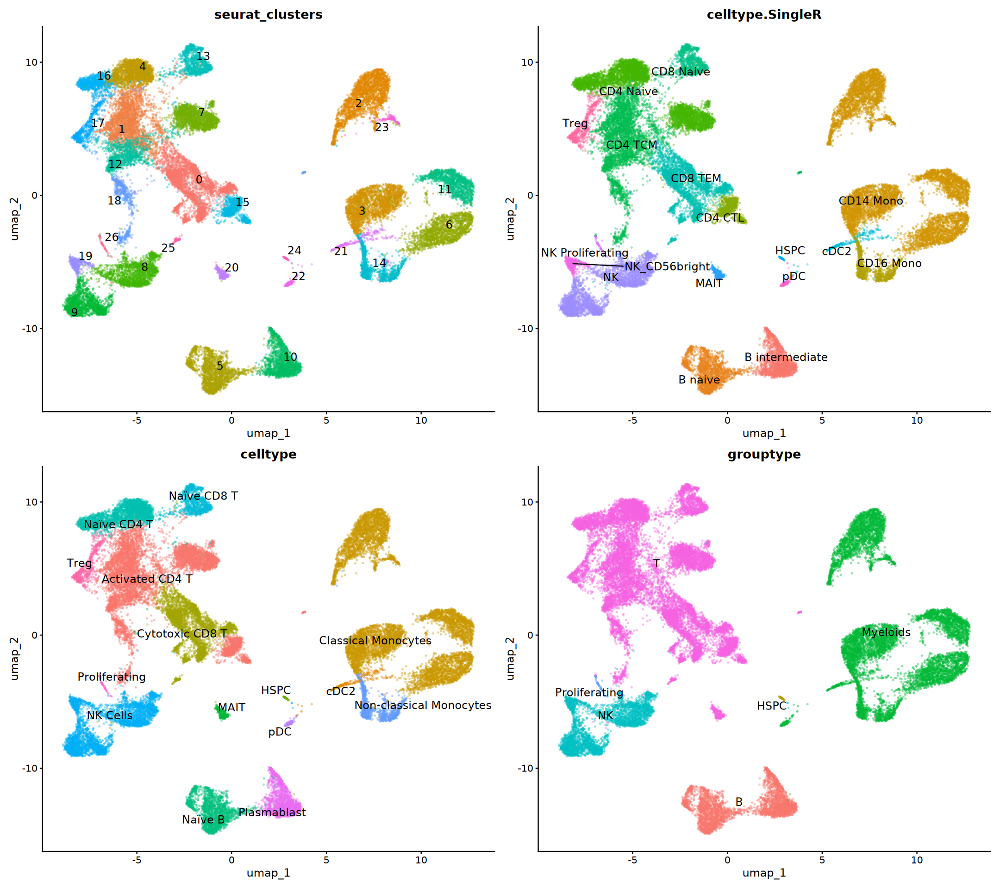

In [122]:
options(repr.plot.width = 18, repr.plot.height = 16)
DimPlot(sc.comb, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR",
                     "celltype", "grouptype"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) & 
    NoLegend()

Warning message:
“ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


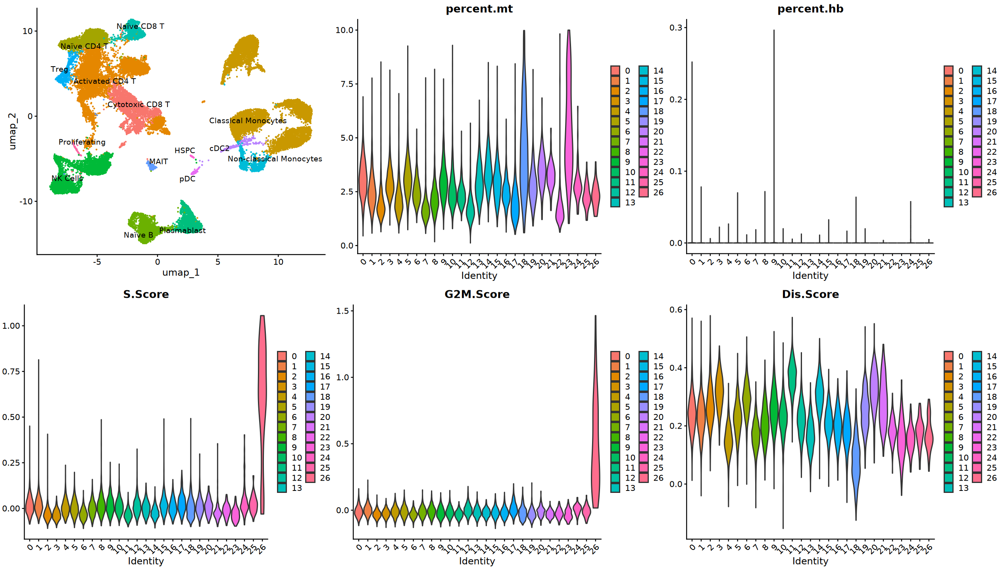

In [123]:
p1 <- DimPlot(
    sc.comb, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- VlnPlot(
    sc.comb, features = c("percent.mt", "percent.hb"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.comb, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

Warning message:
“ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


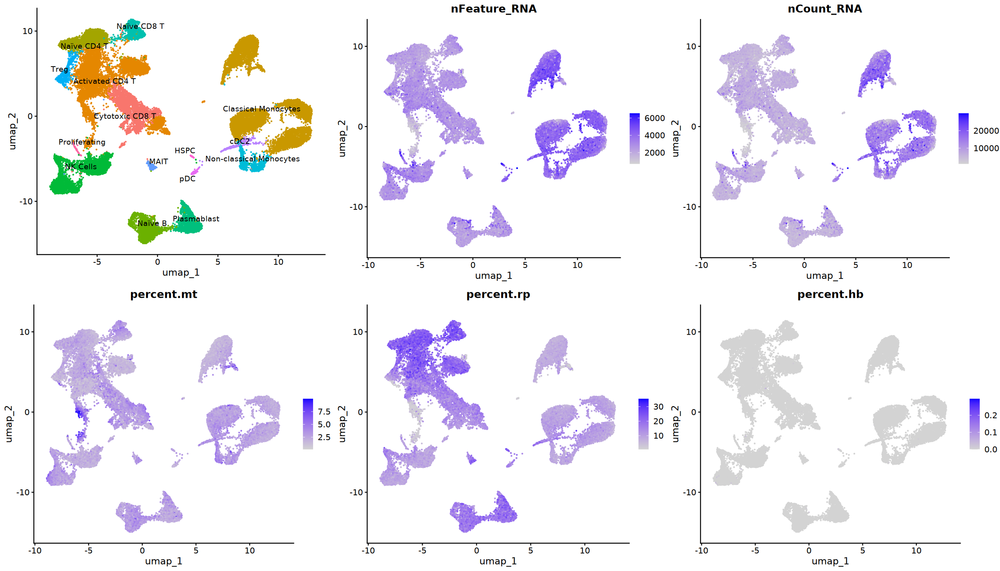

In [124]:
p1 <- DimPlot(
    sc.comb, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- FeaturePlot(
    sc.comb, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [125]:
qs2::qs_save(sc.comb, file.path(
    data_dir, "result", "s11_annotation_seurat_V5.qs2"))